# 12 — Day-30 Model Comparison — Logistic Regression vs Random Forest vs Gradient Boosting

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

Notebooks 10 and 11 found a modest day-30 signal with Logistic Regression. This notebook completes the comparison with the
two ensemble methods from the course, using **exactly the same data, features and splits**:

- **A. Majority baseline**
- **B. Logistic Regression:** `StandardScaler` + `LogisticRegression(max_iter=1000)`
- **C. Random Forest:** 100 trees, `max_depth=4`, `min_samples_leaf=10`
- **D. Gradient Boosting:** 100 small trees, `learning_rate=0.05`, `max_depth=2`, `min_samples_leaf=10`

All settings are fixed (no tuning, class weighting or threshold changes). Tree models do not need scaling.

Same definitions as before: completed cases (`case:endDate` present); **recorded activity span** = last minus first event;
eligible = last event after first event + 30 days; `long_case = 1` if the span is more than 63 days.

The test cases were explored in earlier notebooks, so this is an **exploratory comparison**, not an untouched final evaluation.

## 2. Load the Data and Build the Day-30 Cohort

In [1]:
import os
import warnings
from pathlib import Path

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
# hide only PM4Py's optional speed-up tip ("Install the optional requirement `r4pm` ..."); other warnings still show
warnings.filterwarnings("ignore", message="Install the optional requirement `r4pm`")

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# the project folder: works whether Jupyter starts in the notebooks folder or in the project folder
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_root / "data" / "raw" / "BPIC15_1.xes"



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
log = pm4py.read_xes(str(data_path))
df = pm4py.convert_to_dataframe(log)

case_data = df.groupby("case:concept:name").agg(
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)
case_data = case_data[case_data["end_date"].notna()]   # completed cases only
case_data["long_case"] = (case_data["duration_days"] > 63).astype(int)

case_data["prediction_time"] = case_data["first_event"] + pd.Timedelta(days=30)
active = case_data[case_data["last_event"] > case_data["prediction_time"]]

print("Completed cases:", len(case_data))
print("Day-30 eligible cases:", len(active))

Completed cases: 956
Day-30 eligible cases: 838


## 3. Day-30 Features (Same as Notebooks 10 and 11)

Each case's features use only its own events timestamped on or before its day-30 cutoff, so they can be calculated once for
all eligible cases. Activity indicators are selected later, separately for each training group.

In [3]:
def events_by_day30(event_table, cases):
    # keep only events of the given cases that happened on or before that case's day-30 cutoff
    events = event_table[event_table["case:concept:name"].isin(cases.index)].copy()
    events["prediction_time"] = events["case:concept:name"].map(cases["prediction_time"])
    events["first_event"] = events["case:concept:name"].map(cases["first_event"])
    first30 = events[events["time:timestamp"] <= events["prediction_time"]].copy()
    first30["day"] = (first30["time:timestamp"] - first30["first_event"]).dt.total_seconds() / (24 * 60 * 60)
    return first30

**The seven count features.** `count_columns` fixes their order; `count_features` calculates them for every case from the events kept above.

In [4]:
count_columns = [
    "events_first30",
    "unique_activities_first30",
    "unique_resources_first30",
    "repeated_activities_first30",
    "events_first15",
    "events_days16_30",
    "days_since_last_event",
]


def count_features(first30, cases):
    first30 = first30.copy()
    first30["in_first15"] = first30["day"] <= 15
    features = first30.groupby("case:concept:name").agg(
        events_first30=("concept:name", "size"),
        unique_activities_first30=("concept:name", "nunique"),
        unique_resources_first30=("org:resource", "nunique"),
        events_first15=("in_first15", "sum"),
        last_event_by_day30=("time:timestamp", "max"),
    )
    features["repeated_activities_first30"] = features["events_first30"] - features["unique_activities_first30"]
    features["events_days16_30"] = features["events_first30"] - features["events_first15"]
    features["days_since_last_event"] = (
        cases.loc[features.index, "prediction_time"] - features["last_event_by_day30"]
    ).dt.total_seconds() / (24 * 60 * 60)
    return features[count_columns]

**Apply the helpers** to the cases and check that no event after the cutoff was used.

In [5]:
first30 = events_by_day30(df, active)
counts = count_features(first30, active)
y = active.loc[counts.index, "long_case"]

print("Latest event used, in days after the case start:", first30["day"].max())
print("Every event used is on or before its case's cutoff:", (first30["time:timestamp"] <= first30["prediction_time"]).all())

Latest event used, in days after the case start: 30.0
Every event used is on or before its case's cutoff: True


### Helper functions

Small helpers, because the same steps are repeated in five folds and two final evaluations.

**Choose activity codes using training cases only.** `select_activities` returns the codes recorded in 10–90% of the given cases (at most 15, most frequent first, ties broken by code). It is only ever called with training cases.

In [6]:
def select_activities(first30, case_ids):
    # activity codes recorded in 10-90% of the given cases, at most 15, most frequent first (ties by code)
    events = first30[first30["case:concept:name"].isin(case_ids)]
    share = events.groupby("concept:name")["case:concept:name"].nunique() / len(case_ids) * 100
    share = share.rename("train_cases_pct").reset_index()
    share = share[(share["train_cases_pct"] >= 10) & (share["train_cases_pct"] <= 90)]
    share = share.sort_values(["train_cases_pct", "concept:name"], ascending=[False, True])
    return share.head(15)["concept:name"].tolist()

**Turn the chosen activities into 0/1 columns.** `activity_flags` gives 1 if the activity was recorded by the cutoff in that case, otherwise 0.

In [7]:
def activity_flags(first30, activities, case_ids):
    # 1 if the activity was recorded by day 30 in that case, otherwise 0
    flags = pd.DataFrame(index=case_ids)
    for activity in activities:
        cases_with_activity = first30.loc[first30["concept:name"] == activity, "case:concept:name"].unique()
        flags["act_" + activity] = flags.index.isin(cases_with_activity).astype(int)
    return flags

**Build the feature table** for a list of cases: the seven counts plus the activity indicators.

In [8]:
def make_X(case_ids, activities):
    # seven counts + activity indicators for the given cases
    return counts.loc[case_ids].join(activity_flags(first30, activities, case_ids))

**Fit the approaches** with the same fixed settings every time (no tuning). Logistic Regression is a pipeline, so its scaler is fitted on the training cases only. The tree models do not need scaling.

In [9]:
def fit_four_models(X_train, y_train):
    return {
        "A. Majority baseline": DummyClassifier(strategy="most_frequent").fit(X_train, y_train),
        "B. Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train),
        "C. Random Forest": RandomForestClassifier(
            n_estimators=100, max_depth=4, min_samples_leaf=10, random_state=42).fit(X_train, y_train),
        "D. Gradient Boosting": GradientBoostingClassifier(
            n_estimators=100, learning_rate=0.05, max_depth=2, min_samples_leaf=10, random_state=42).fit(X_train, y_train),
    }

**Score a fitted model.** Accuracy, precision, recall and F1 use the 0/1 predictions (threshold 0.5); ROC-AUC uses the predicted probabilities.

In [10]:
def score(model, X, y_true):
    predictions = model.predict(X)
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions),
        "F1": f1_score(y_true, predictions),
        "ROC-AUC": roc_auc_score(y_true, model.predict_proba(X)[:, 1]),
        "Cases flagged long": int(predictions.sum()),
    }

**Show a confusion matrix** as a small labelled table.

In [11]:
def show_confusion_matrix(model, X, y_true):
    return pd.DataFrame(
        confusion_matrix(y_true, model.predict(X)),
        index=["actual 0 (not long)", "actual 1 (long)"],
        columns=["predicted 0", "predicted 1"],
    )

## 4. Random Split (Same as Notebook 10)

The original train/test split from notebooks 07–08 is rebuilt with the same code and filtered to day-30 cases, so the
training and test groups (and the order of the training cases, which decides the folds) are the same as in notebook 10.
Same inputs and settings as notebooks 07 and 10, so `train_test_split` returns exactly the same groups; the checks below
confirm the sizes, numbers of long cases, overlap and subset membership.

In [12]:
day14_cases = case_data[case_data["last_event"] > case_data["first_event"] + pd.Timedelta(days=14)]
original_train_ids, original_test_ids = train_test_split(
    day14_cases.index, test_size=0.20, random_state=42, stratify=day14_cases["long_case"]
)

random_train_ids = [case for case in original_train_ids if case in active.index]
random_test_ids = [case for case in original_test_ids if case in active.index]

print("Training cases:", len(random_train_ids), "| long:", y.loc[random_train_ids].sum())
print("Test cases:", len(random_test_ids), "| long:", y.loc[random_test_ids].sum())
print("Overlap:", len(set(random_train_ids) & set(random_test_ids)))
print("All day-30 cases are in the original split:", set(active.index) <= set(original_train_ids) | set(original_test_ids))

Training cases: 677 | long: 377
Test cases: 161 | long: 95
Overlap: 0
All day-30 cases are in the original split: True


### Cross-validation on the random training cases

Five stratified folds: the models are trained and checked on five different portions of the training data. In each fold the
activities are selected on that fold's training part only, and all four approaches use the same fold and the same features.

In [13]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_index = pd.Index(random_train_ids)   # lets us turn fold positions into case IDs

cv_rows = []
validated_ids = []
for fold, (fit_positions, val_positions) in enumerate(folds.split(train_index, y.loc[train_index]), start=1):
    fit_ids = train_index[fit_positions]
    val_ids = train_index[val_positions]
    validated_ids += list(val_ids)

    activities = select_activities(first30, fit_ids)
    models = fit_four_models(make_X(fit_ids, activities), y.loc[fit_ids])
    X_val = make_X(val_ids, activities)
    for name, model in models.items():
        cv_rows.append({"Fold": fold, "Approach": name, **score(model, X_val, y.loc[val_ids])})

cv_results = pd.DataFrame(cv_rows)
print("Validated cases:", len(validated_ids), "of", len(train_index))
print("Every training case validated:", set(validated_ids) == set(train_index))
print("No case validated twice:", len(validated_ids) == len(set(validated_ids)))

Validated cases: 677 of 677
Every training case validated: True
No case validated twice: True


In [14]:
metric_columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
cv_results.groupby("Approach")[metric_columns].agg(["mean", "std"]).round(3)

Accuracy        Precision        Recall            F1  \
                           mean    std      mean    std   mean    std   mean   
Approach                                                                       
A. Majority baseline      0.557  0.002     0.557  0.002  1.000  0.000  0.715   
B. Logistic Regression    0.644  0.030     0.668  0.026  0.719  0.036  0.692   
C. Random Forest          0.646  0.022     0.648  0.013  0.799  0.089  0.713   
D. Gradient Boosting      0.612  0.028     0.624  0.010  0.764  0.126  0.683   

                              ROC-AUC         
                          std    mean    std  
Approach                                      
A. Majority baseline    0.001   0.500  0.000  
B. Logistic Regression  0.028   0.702  0.033  
C. Random Forest        0.033   0.701  0.042  
D. Gradient Boosting    0.052   0.684  0.044

In [15]:
cv_results.pivot(index="Fold", columns="Approach", values="ROC-AUC").round(3)

Approach,A. Majority baseline,B. Logistic Regression,C. Random Forest,D. Gradient Boosting
Fold,,,,
1,0.5,0.755,0.732,0.693
2,0.5,0.667,0.656,0.647
3,0.5,0.707,0.720,0.702
4,0.5,0.683,0.656,0.636
5,0.5,0.698,0.740,0.744


The standard deviation shows how much results vary between the five folds. It is not a confidence interval.

### Final evaluation on the random test cases

Activities are selected on all random training cases; each fixed approach is fitted once and scored once.

In [16]:
random_activities = select_activities(first30, random_train_ids)
X_random_train = make_X(random_train_ids, random_activities)
X_random_test = make_X(random_test_ids, random_activities)
y_random_train = y.loc[random_train_ids]
y_random_test = y.loc[random_test_ids]

random_models = fit_four_models(X_random_train, y_random_train)

random_results = {}
for name, model in random_models.items():
    random_results[name] = score(model, X_random_test, y_random_test)
random_results = pd.DataFrame(random_results).T
random_results["Cases flagged long"] = random_results["Cases flagged long"].astype(int)

print(f"Random test cases: {len(y_random_test)} | share of long cases: {y_random_test.mean():.1%}")
random_results.round(3)

Random test cases: 161 | share of long cases: 59.0%


,Accuracy,Precision,Recall,F1,ROC-AUC,Cases flagged long
A. Majority baseline,0.590,0.590,1.000,0.742,0.500,161
B. Logistic Regression,0.646,0.694,0.716,0.705,0.659,98
C. Random Forest,0.696,0.695,0.863,0.770,0.745,118
D. Gradient Boosting,0.677,0.697,0.800,0.745,0.723,109


In [17]:
for name in ["C. Random Forest", "D. Gradient Boosting"]:
    print(name)
    print(show_confusion_matrix(random_models[name], X_random_test, y_random_test))
    print()

C. Random Forest
                     predicted 0  predicted 1
actual 0 (not long)           30           36
actual 1 (long)               13           82

D. Gradient Boosting
                     predicted 0  predicted 1
actual 0 (not long)           33           33
actual 1 (long)               19           76



## 5. Temporal Split (Same Rules as Notebook 11)

Sort by `prediction_time`; the boundary is the `prediction_time` at the start of the final 20%; test = at or after the
boundary; training = before the boundary **and** with `last_event` and `case:endDate` both before the boundary.

In [18]:
sorted_cases = active.sort_values("prediction_time", kind="stable")
boundary = sorted_cases["prediction_time"].iloc[int(len(sorted_cases) * 0.8)]

temporal_test = sorted_cases[sorted_cases["prediction_time"] >= boundary]
candidates = sorted_cases[sorted_cases["prediction_time"] < boundary]
temporal_train = candidates[(candidates["last_event"] < boundary) & (candidates["end_date"] < boundary)]
temporal_train_ids, temporal_test_ids = temporal_train.index, temporal_test.index

print("Boundary:", boundary)
print("Training cases:", len(temporal_train_ids), "| long:", y.loc[temporal_train_ids].sum())
print("Test cases:", len(temporal_test_ids), "| long:", y.loc[temporal_test_ids].sum())
print("Overlap:", len(set(temporal_train_ids) & set(temporal_test_ids)))
print("Training dates all before the boundary:",
      (temporal_train["last_event"] < boundary).all() and (temporal_train["end_date"] < boundary).all())

Boundary: 2013-10-25 22:00:00+00:00
Training cases: 617 | long: 328
Test cases: 168 | long: 100
Overlap: 0
Training dates all before the boundary: True


In [19]:
temporal_activities = select_activities(first30, temporal_train_ids)
X_temporal_train = make_X(temporal_train_ids, temporal_activities)
X_temporal_test = make_X(temporal_test_ids, temporal_activities)
y_temporal_train = y.loc[temporal_train_ids]
y_temporal_test = y.loc[temporal_test_ids]

temporal_models = fit_four_models(X_temporal_train, y_temporal_train)

temporal_results = {}
for name, model in temporal_models.items():
    temporal_results[name] = score(model, X_temporal_test, y_temporal_test)
temporal_results = pd.DataFrame(temporal_results).T
temporal_results["Cases flagged long"] = temporal_results["Cases flagged long"].astype(int)

print(f"Temporal test cases: {len(y_temporal_test)} | share of long cases: {y_temporal_test.mean():.1%}")
temporal_results.round(3)

Temporal test cases: 168 | share of long cases: 59.5%


,Accuracy,Precision,Recall,F1,ROC-AUC,Cases flagged long
A. Majority baseline,0.595,0.595,1.00,0.746,0.500,168
B. Logistic Regression,0.637,0.775,0.55,0.643,0.678,71
C. Random Forest,0.613,0.843,0.43,0.570,0.674,51
D. Gradient Boosting,0.583,0.875,0.35,0.500,0.624,40


In [20]:
for name in ["C. Random Forest", "D. Gradient Boosting"]:
    print(name)
    print(show_confusion_matrix(temporal_models[name], X_temporal_test, y_temporal_test))
    print()

C. Random Forest
                     predicted 0  predicted 1
actual 0 (not long)           60            8
actual 1 (long)               57           43

D. Gradient Boosting
                     predicted 0  predicted 1
actual 0 (not long)           63            5
actual 1 (long)               65           35



## 6. Check: Baseline and Logistic Regression Reproduce Notebooks 10 and 11

This is a consistency check: the values below are the outputs of notebooks 10 and 11 (rounded to 3 decimals). If they did not match, the ensemble results
could not be compared fairly.

In [21]:
recorded = {
    ("random test", "A. Majority baseline"): [0.590, 0.590, 1.000, 0.742, 0.500],
    ("random test", "B. Logistic Regression"): [0.646, 0.694, 0.716, 0.705, 0.659],
    ("temporal test", "A. Majority baseline"): [0.595, 0.595, 1.000, 0.746, 0.500],
    ("temporal test", "B. Logistic Regression"): [0.637, 0.775, 0.550, 0.643, 0.678],
    ("cross-validation mean", "A. Majority baseline"): [0.557, 0.557, 1.000, 0.715, 0.500],
    ("cross-validation mean", "B. Logistic Regression"): [0.644, 0.668, 0.719, 0.692, 0.702],
}
cv_means = cv_results.groupby("Approach")[metric_columns].mean()
current = {"random test": random_results, "temporal test": temporal_results, "cross-validation mean": cv_means}

all_match = True
for (where, name), values in recorded.items():
    now = current[where].loc[name, metric_columns].astype(float).round(3).tolist()
    match = all(abs(a - b) < 0.0011 for a, b in zip(now, values))
    all_match = all_match and match
    print(f"{where:>22} | {name:<24} | matches: {match}")
assert all_match, "Baseline / Logistic Regression do not reproduce notebooks 10 and 11"

           random test | A. Majority baseline     | matches: True
           random test | B. Logistic Regression   | matches: True
         temporal test | A. Majority baseline     | matches: True
         temporal test | B. Logistic Regression   | matches: True
 cross-validation mean | A. Majority baseline     | matches: True
 cross-validation mean | B. Logistic Regression   | matches: True


## 7. Side-by-Side ROC-AUC

In [22]:
roc_table = pd.DataFrame({
    "Cross-validation mean": cv_means["ROC-AUC"],
    "Cross-validation std": cv_results.groupby("Approach")["ROC-AUC"].std(),
    "Random test": random_results["ROC-AUC"],
    "Temporal test": temporal_results["ROC-AUC"],
}).astype(float)
roc_table.round(3)

,Cross-validation mean,Cross-validation std,Random test,Temporal test
A. Majority baseline,0.500,0.000,0.500,0.500
B. Logistic Regression,0.702,0.033,0.659,0.678
C. Random Forest,0.701,0.042,0.745,0.674
D. Gradient Boosting,0.684,0.044,0.723,0.624


### ROC-AUC chart

The same numbers as the table. The black error bars show **±1 standard deviation across the five folds**; they describe how
much the folds differ and are **not** confidence intervals. The dashed line is the majority baseline (0.50, no ranking).

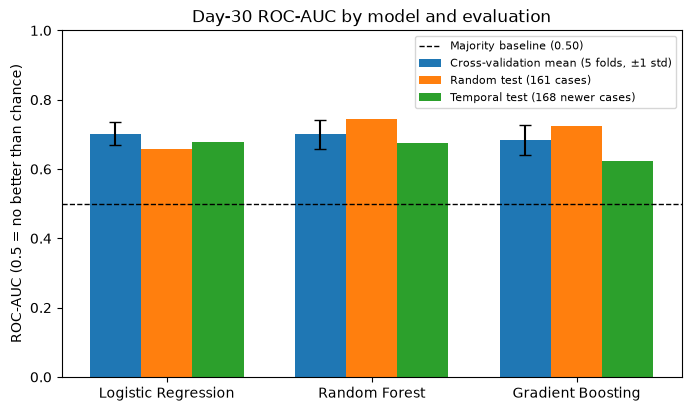

In [23]:
models_to_plot = ["B. Logistic Regression", "C. Random Forest", "D. Gradient Boosting"]
positions = [0, 1, 2]
width = 0.25

plt.figure(figsize=(8, 4.5))
plt.bar([p - width for p in positions], roc_table.loc[models_to_plot, "Cross-validation mean"], width,
        yerr=roc_table.loc[models_to_plot, "Cross-validation std"], capsize=4,
        label="Cross-validation mean (5 folds, ±1 std)")
plt.bar(positions, roc_table.loc[models_to_plot, "Random test"], width, label="Random test (161 cases)")
plt.bar([p + width for p in positions], roc_table.loc[models_to_plot, "Temporal test"], width,
        label="Temporal test (168 newer cases)")
plt.axhline(0.5, color="black", linestyle="--", linewidth=1, label="Majority baseline (0.50)")
plt.xticks(positions, ["Logistic Regression", "Random Forest", "Gradient Boosting"])
plt.ylim(0, 1)
plt.ylabel("ROC-AUC (0.5 = no better than chance)")
plt.title("Day-30 ROC-AUC by model and evaluation")
plt.legend(loc="upper right", fontsize=8)
plt.show()

### Temporal test: Logistic Regression confusion matrix

How the main model's warnings look on the 168 newer cases, at the default threshold of 0.5.

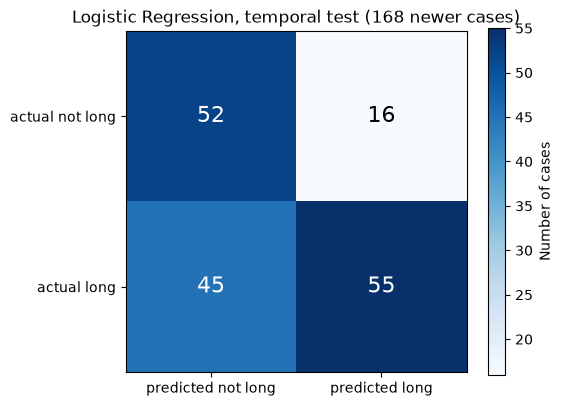

In [24]:
matrix = confusion_matrix(y_temporal_test, temporal_models["B. Logistic Regression"].predict(X_temporal_test))

plt.figure(figsize=(5.5, 4.5))
plt.imshow(matrix, cmap="Blues")
for i in range(2):
    for j in range(2):
        text_color = "white" if matrix[i, j] > matrix.max() / 2 else "black"
        plt.text(j, i, matrix[i, j], ha="center", va="center", fontsize=16, color=text_color)
plt.xticks([0, 1], ["predicted not long", "predicted long"])
plt.yticks([0, 1], ["actual not long", "actual long"])
plt.colorbar(label="Number of cases")
plt.title("Logistic Regression, temporal test (168 newer cases)")
plt.show()

## 8. Interpretation

**Does either ensemble improve on Logistic Regression?** Only on one of the three evaluations.

| ROC-AUC | Cross-validation | Random test | Temporal test |
|---|---|---|---|
| B. Logistic Regression | 0.702 | 0.659 | 0.678 |
| C. Random Forest | 0.701 | 0.745 | 0.674 |
| D. Gradient Boosting | 0.684 | 0.723 | 0.624 |

- **Cross-validation:** Random Forest and Logistic Regression are practically equal (0.701 vs 0.702); Gradient Boosting is
  slightly lower. The fold-to-fold variation (about 0.03–0.05) is larger than these differences.
- **Random test:** both ensembles score higher than Logistic Regression (0.745 and 0.723 vs 0.659).
- **Temporal test (older → newer cases):** Random Forest is about equal to Logistic Regression (0.674 vs 0.678), and Gradient
  Boosting is lower (0.624).

So the ensemble advantage appears on **one test set only**, and not in cross-validation or the temporal check. One test set of
161 cases is not enough to show a real improvement.

**Warnings (precision and recall) are less stable for the ensembles.** On the random test, Random Forest flags 118 of 161
cases (recall 0.863); on the temporal test it flags only 51 of 168 (recall 0.43), and Gradient Boosting only 40 (recall 0.35).
Their warnings are very often correct on the temporal test (precision 0.84–0.88), but they miss most long cases there.
Logistic Regression changes less between the two tests (recall 0.716 and 0.55).

On the temporal test the confusion matrix shows the trade-off: of the 71 cases Logistic Regression flags, 55 are long
(77.5% precision), but 45 of the 100 long cases are missed (recall 0.55).

**Recommendation:** keep **Logistic Regression** as the main day-30 model. The ensembles do not show a consistent gain across
cross-validation, the random test and the temporal test, they are harder to explain, and their warning behaviour changes more
between test sets. When scores are similar, the simpler model is preferred.

The test cases were already used in earlier notebooks, and 138 of the 168 temporal test cases were random-split training
cases, so this is an **exploratory comparison**, not an untouched final evaluation.

## 9. Limitations

- One Dutch municipality; not SPAR or Montenegro data.
- Retrospective cohort: historically completed cases whose recorded span extends beyond day 30; the target is the **recorded activity span**, not a verified completion time.
- Event timestamps are assumed to show information available by day 30; this cannot be proven from the log.
- Fixed settings were used for every model; other settings could give different results, but tuning was not part of this task.